# **Lab 8 - Edge Detection**


**Objective:** Apply and compare Sobel, Prewitt, and Canny edge detection, then investigate the effect of Canny thresholds.



In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# New image: coffee photograph (RGB), not the reference image
img = data.coffee()
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# Use the same preprocessing for all methods and threshold pairs
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

## **Task 1 - Apply Edge Detection Methods**

### **Sobel Edge Detector**
Calculate horizontal and vertical derivatives, then combine their magnitudes. Normalize the magnitude before converting to uint8 to avoid value wraparound.

In [7]:
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

### **Prewitt Edge Detector**
Define the two 3x3 kernels and apply them using OpenCV. Combine and normalize the gradient magnitude.

In [8]:
kernel_x = np.array([
    [-1, 0, 1], [-1, 0, 1], [-1, 0, 1]
], dtype=np.float64)
kernel_y = np.array([
    [-1, -1, -1], [0, 0, 0], [1, 1, 1]
], dtype=np.float64)

prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_edges = cv2.normalize(
    prewitt_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

### **Canny Edge Detector**
Use low = 50 and high = 150 for the initial comparison.

In [9]:
canny_edges = cv2.Canny(blurred, 50, 150)

### **Display the Original and Three Edge Maps**

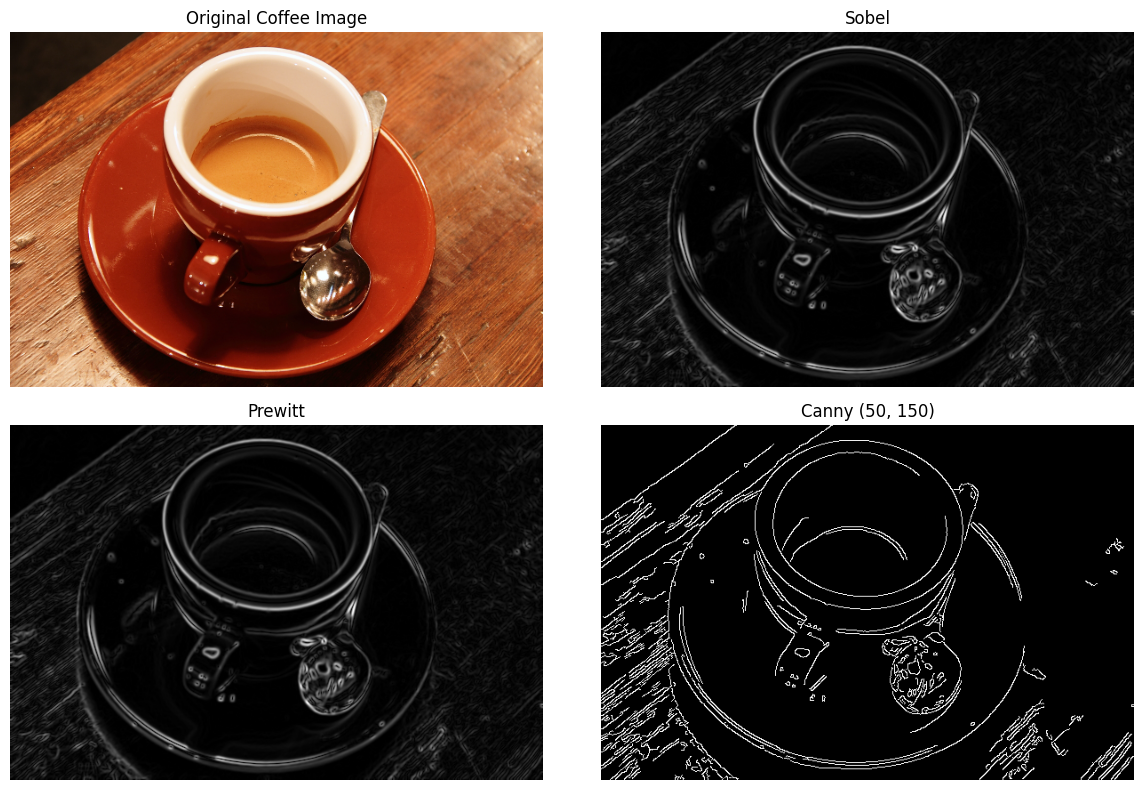

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
images = [img, sobel_edges, prewitt_edges, canny_edges]
titles = ["Original Coffee Image", "Sobel", "Prewitt", "Canny (50, 150)"]

for a, result, title in zip(ax.flat, images, titles):
    if result.ndim == 3:
        a.imshow(result)
    else:
        a.imshow(result, cmap="gray", vmin=0, vmax=255)
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

**Comparison:** Sobel and Prewitt produce gradient-strength maps with similar outlines and soft edge responses. Each is normalized separately for visibility, so brightness is not a direct comparison of their raw magnitudes. Canny produces thin binary edges and suppresses many weaker responses.

## **Task 2 - Investigate Canny Thresholds**

Apply exactly the three required threshold pairs to the same blurred grayscale image. Only the thresholds change.

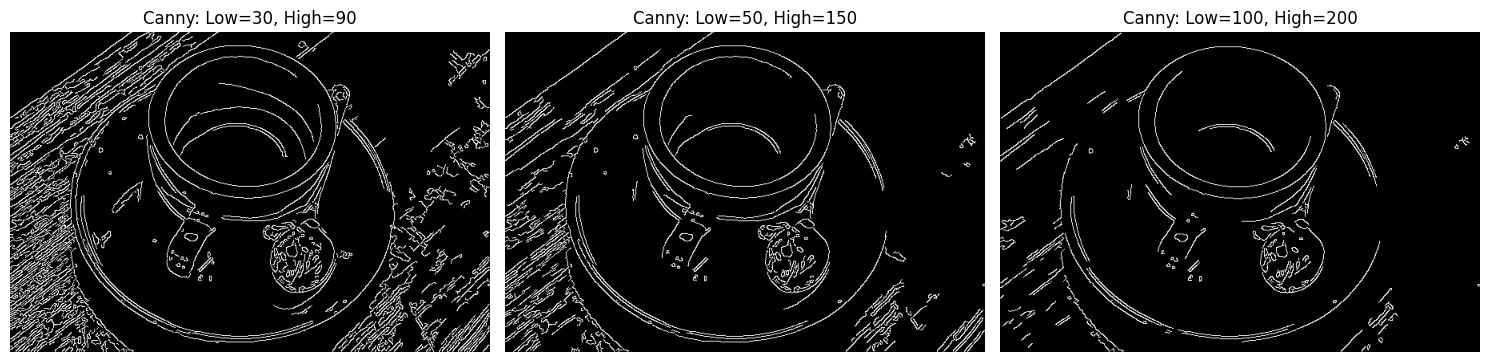

Low   High   Edge pixels
30    90     24319
50    150    13823
100   200    7790


In [10]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_results = []
edge_counts = []

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (low, high) in zip(ax, threshold_pairs):
    edges = cv2.Canny(blurred, low, high)
    canny_results.append(edges)
    edge_counts.append(int(np.count_nonzero(edges)))
    a.imshow(edges, cmap="gray", vmin=0, vmax=255)
    a.set_title(f"Canny: Low={low}, High={high}")
    a.axis("off")

plt.tight_layout()
plt.show()

print("Low   High   Edge pixels")
for (low, high), count in zip(threshold_pairs, edge_counts):
    print(f"{low:<5} {high:<6} {count}")

### **Effect of Changing the Thresholds**

- **Low = 30, High = 90:** 24,319 edge pixels. More weak edges and fine details are retained, including extra texture that may be distracting.
- **Low = 50, High = 150:** 13,823 edge pixels. Some weaker texture is removed while major object outlines remain visible.
- **Low = 100, High = 200:** 7,790 edge pixels. Fewer edges survive; strong boundaries remain, but faint details are lost.

The high threshold identifies strong edge candidates. Responses between the low and high thresholds survive only when connected to strong edges through candidate edge pixels; responses below the low threshold are rejected. Increasing both thresholds therefore makes detection more selective. All three runs use identical grayscale conversion and Gaussian blur, making the threshold comparison fair.

**Conclusion:** Sobel and Prewitt show edge strength, while Canny produces thin binary contours. Lower Canny thresholds retain more detail; higher thresholds favor stronger boundaries and reduce the number of detected edges.